In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [17]:
# 1. Загрузка данных
train_df = pd.read_csv("/content/train.csv")
final_df = pd.read_csv("/content/test_features.csv")

# Убираем из признаков patient_id и prediction
X = train_df.drop(columns=["patient_id", "prediction"]).values.astype(np.float32)

y = train_df["prediction"].values.astype(np.float32).reshape(-1, 1)

# Признаки для финального предсказания
X_final = final_df.drop(columns=["patient_id"]).values.astype(np.float32)

print(f"Признаков: {X.shape[1]}, Объектов: {X.shape[0]}")
print(f"Классы: 0 = {(y == 0).sum()} объектов, 1 = {(y == 1).sum()} объектов")

Признаков: 17, Объектов: 800
Классы: 0 = 655 объектов, 1 = 145 объектов


In [18]:
# 2. Разбиение на train/test

# X_train — на них модель учится, X_test — на них проверяем качество
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

Делим train.csv на обучающую и проверочную части, чтобы оценить качество на данных, которые модель не видела. Stratify=y сохраняет одинаковую долю класса 1 в обеих частях

In [19]:
# 3. Пропуски и нормализация признаков

# Заполняием пропуски
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
X_final = imputer.transform(X_final)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_final = scaler.transform(X_final)

Заполняем пропуски медианой и приводим признаки к одному масштабу

In [20]:
# 4. Преобразование в тензоры
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)
X_final_t = torch.tensor(X_final, dtype=torch.float32)

Переводим numpy-массивы в тензоры PyTorch, с которыми работает нейросеть

In [21]:
# 5. DataLoader

# DataLoader упаковывает данные и подаёт их в модель небольшими порциями
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

DataLoader подаёт данные в модель порциями, батчами по 32. Train перемешиваем на каждой эпохе, test — нет

In [22]:
# 6. Определение модели FFN
class PatientFFN(nn.Module):
  def __init__(self, input_dim):
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 64)
    self.fc2 = nn.Linear(64, 32)
    self.fc3 = nn.Linear(32, 1)
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(0.2)

  def forward(self, x):
    x = self.relu(self.fc1(x))
    x = self.dropout(x)
    x = self.relu(self.fc2(x))
    x = self.fc3(x)
    return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PatientFFN(X_train.shape[1]).to(device)

В FFN данные идут строго от входа к выходу через несколько полносвязных слоёв

In [23]:
# 7. Функция потерь и оптимизатор
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Функция потерь показывает насколько предсказания модели далеки от правильных ответов

In [24]:
# 8. Цикл обучения
epochs = 100   # эпоха = один полный проход по всем обучающим данным
train_losses, test_losses = [], []

for epoch in range(epochs):

    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)


    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    epoch_test_loss = val_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} — Train Loss: {epoch_train_loss:.4f}, Test Loss: {epoch_test_loss:.4f}")

Epoch 20/100 — Train Loss: 0.0869, Test Loss: 0.1523
Epoch 40/100 — Train Loss: 0.0540, Test Loss: 0.1561
Epoch 60/100 — Train Loss: 0.0304, Test Loss: 0.1908
Epoch 80/100 — Train Loss: 0.0128, Test Loss: 0.1907
Epoch 100/100 — Train Loss: 0.0076, Test Loss: 0.2088


На каждой эпохе: обучаемся на train, затем считаем ошибку на test без обучения. Запоминаем веса лучшей эпохи, потому что к концу модель переобучается

In [25]:
# 9. Оценка модели
model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)
        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

Получаем вероятности класса 1 и переводим их в классы по порогу. Порог 0.5 — стандартный

In [26]:
# 10. Метрики

print("\n" + "="*50)
print("Оценка на тестовой выборке:")
print("="*50)
print(f"Accuracy:  {accuracy_score(y_true, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_true, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred_class):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, y_pred_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_class))


Оценка на тестовой выборке:
Accuracy:  0.9375
Precision: 0.8800
Recall:    0.7586
F1-score:  0.8148
ROC-AUC:   0.9860

Confusion Matrix:
[[128   3]
 [  7  22]]


Accuracy — доля правильных ответов

Precision — из всех предсказанных положительных, сколько действительно положительных

Recall — из всех реальных положительных, сколько мы нашли

F1-score — гармоническое среднее между Precision и Recall

ROC-AUC — площадь под ROC-кривой; показывает, насколько хорошо модель разделяет классы


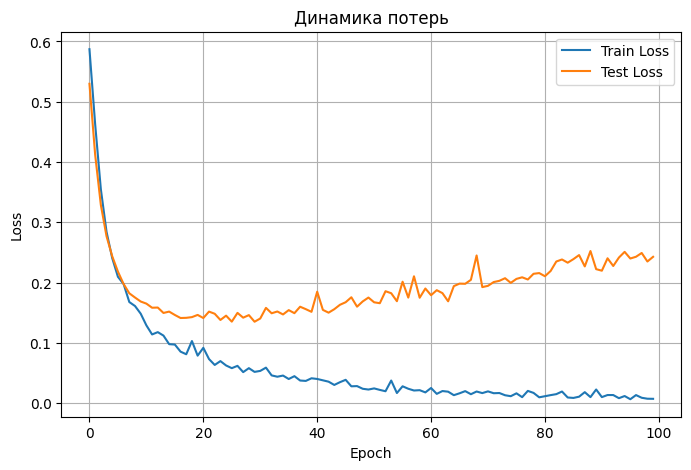

In [12]:
# 11. График потерь
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()

Если Train Loss падает, а Test Loss растёт — это переобучение. Минимум Test Loss показывает лучший момент остановки

In [13]:
# 12. Предсказания для test_features.csv
import os

model.eval()
with torch.no_grad():
    final_logits = model(X_final_t.to(device))
    final_prob = torch.sigmoid(final_logits).cpu().numpy().flatten()

submission = pd.DataFrame({
    "patient_id": final_df["patient_id"],
    "prediction": (final_prob >= 0.5).astype(int)
})

assert len(submission) == len(final_df)
assert submission["patient_id"].tolist() == final_df["patient_id"].tolist()
assert submission.notna().all().all()

os.makedirs("outputs", exist_ok=True)
submission.to_csv("outputs/task1_predictions.csv", index=False)
print(f"Сохранено строк: {len(submission)}")
submission.head()

Сохранено строк: 200


,patient_id,prediction
0,2,0
1,3,0
2,8,0
3,18,0
4,19,0


Предсказываем класс для финальных пациентов тем же порогом и сохраняем файл